
# Lab 2 - Exercise 2: Coin and Dice Game

## a) Distribution of N

The game ends when the first player gets heads for the first time.

Therefore, the number of steps N follows a **geometric distribution** with probability p = 0.5 for a fair coin.

$$
P(N=n)=(1-p)^{n-1}p
$$

The expected number of steps is:

$$
E[N]=\frac{1}{p}=\frac{1}{0.5}=2
$$

This means that the game lasts 2 steps on average.



## b) Simulation of the Game

We simulate a game between two players.

The first player flips a coin:

- If the result is tails, the first player pays $0.50 to the second player, and the game continues.
- If the result is heads, the second player rolls a die and pays the first player an amount equal to the dice result minus 3 dollars. The game ends.

We calculate two variables:
- **N:** Number of steps until the game ends.
- **S:** Total amount of money received by the first player from the second player.


In [22]:

import random

# Initial values
N = 0
S = 0

while True:
    N += 1

    # Flip the coin
    coin = random.choice(["heads", "tails"])

    if coin == "heads":
        # Roll the die and end the game
        dice = random.randint(1, 6)
        S += dice - 3
        break
    else:
        # First player pays $0.50
        S -= 0.5

print("Number of steps (N):", N)
print("Total amount (S):", S, "$")


Number of steps (N): 3
Total amount (S): -3.0 $



## c) Simulation of Multiple Games

We simulate 100,000 games to estimate the average value of S.

For each game, we calculate the total amount of money received by the first player.

Finally, we calculate the mean of S and represent its distribution using a histogram.


Number of simulations: 100000
Average S: 0.013085


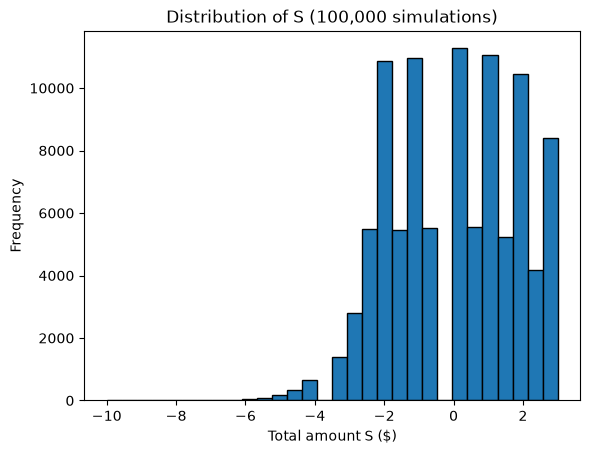

In [23]:

import matplotlib.pyplot as plt

# Number of simulations
n = 100000
results = []

for i in range(n):
    S = 0

    while True:
        coin = random.choice(["heads", "tails"])

        if coin == "heads":
            dice = random.randint(1, 6)
            S += dice - 3
            break
        else:
            S -= 0.5

    results.append(S)

# Calculate the average
average_S = sum(results) / n

print("Number of simulations:", n)
print("Average S:", average_S)

# Plot the histogram
plt.hist(results, bins=30, edgecolor="black")
plt.xlabel("Total amount S ($)")
plt.ylabel("Frequency")
plt.title("Distribution of S (100,000 simulations)")
plt.show()



### Conclusion

After simulating 100,000 games, the estimated average value of S is **0.013085 dollars**.

The theoretical expected value is **0 dollars**, so the simulated result is very close to the theoretical value.

The histogram shows that most games produce results close to zero, while larger losses are less frequent.

Therefore, the simulation is consistent with the theoretical result.



## d) Simulation with Biased Coins

We repeat the simulation using two biased coins:

- **p = 0.3:** The probability of getting heads is 30%.
- **p = 0.7:** The probability of getting heads is 70%.

We simulate 100,000 games for each probability and compare the average values of S and their histograms.


Probability of heads: 0.3
Average S: -0.671995



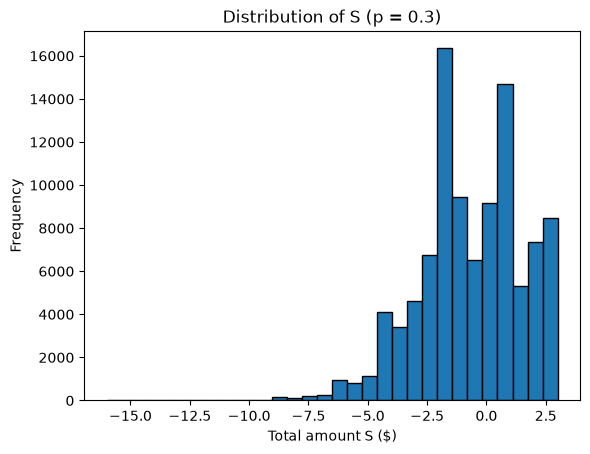

Probability of heads: 0.7
Average S: 0.281745



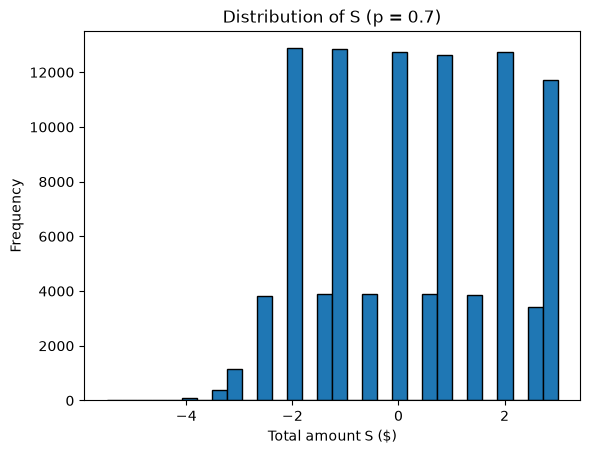

In [24]:

import matplotlib.pyplot as plt

# Number of simulations
n = 100000

for p in [0.3, 0.7]:
    results = []

    for i in range(n):
        S = 0

        while True:
            # Flip the biased coin
            if random.random() < p:
                # Heads: roll the die and end the game
                dice = random.randint(1, 6)
                S += dice - 3
                break
            else:
                # Tails: first player pays $0.50
                S -= 0.5

        results.append(S)

    # Calculate the average
    average_S = sum(results) / n

    print("Probability of heads:", p)
    print("Average S:", average_S)
    print()

    # Plot the histogram
    plt.hist(results, bins=30, edgecolor="black")
    plt.xlabel("Total amount S ($)")
    plt.ylabel("Frequency")
    plt.title(f"Distribution of S (p = {p})")
    plt.show()



### Conclusion

After simulating 100,000 games for each biased coin, we obtained the following results:

- **p = 0.3:** The estimated average S is **-0.671995 dollars**, close to the theoretical value of **-0.666667 dollars**.
- **p = 0.7:** The estimated average S is **0.281745 dollars**, close to the theoretical value of **0.285714 dollars**.

When p = 0.3, the game tends to last longer, resulting in more losses for the first player.

When p = 0.7, the game tends to end sooner, resulting in a positive average gain.

Therefore, increasing the probability of heads increases the expected gain of the first player. The simulation results agree with the theoretical values.
